# Segmentasi Otsu dan Operasi Morfologi

**Nama:** Andi Nabil Safaraz
**NIM:** 25/560270/PA/23603

Pada percobaan ini saya membuat segmentasi Otsu dan empat operasi dasar morfologi secara manual, kemudian membandingkan hasil sebelum dan sesudah morfologi.

## 1 Import library

Pada percobaan ini saya memakai Pillow untuk membaca gambar dan Matplotlib untuk menampilkan hasil. Perhitungan grayscale, segmentasi, dan morfologi dibuat sendiri. Modul random dipakai untuk membuat kondisi uji dengan noise, sedangkan os dipakai untuk mengatur lokasi file.

In [1]:
from PIL import Image
import matplotlib.pyplot as plt
import random
import os


## 2 Membuat matriks kosong

Sebelum mulai, saya membuat fungsi buat_matriks() untuk menyiapkan tempat menyimpan hasil. Fungsi ini membuat baris dan kolom sesuai ukuran gambar, kemudian mengisi seluruh nilainya dengan 0.

In [2]:
def buat_matriks(tinggi, lebar):
    hasil = []

    for y in range(tinggi):
        baris = []
        for x in range(lebar):
            baris.append(0)
        hasil.append(baris)

    return hasil


## 3 Membaca gambar dan menghitung grayscale

Gambar yang digunakan adalah coins.png. Setelah dibaca, setiap piksel diubah menjadi grayscale dengan bobot 0,299 untuk merah, 0,587 untuk hijau, dan 0,114 untuk biru.

Ukuran gambar: 384 x 303


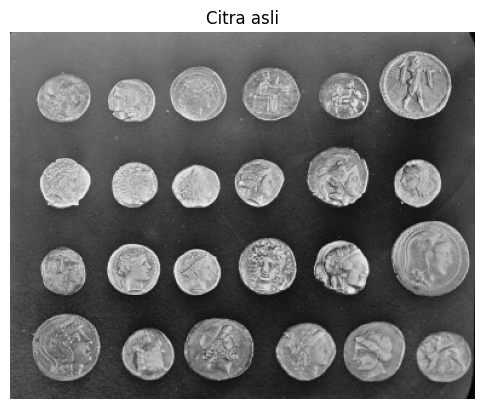

In [3]:
nama_file = "coins.png"

if not os.path.exists(nama_file):
    nama_file = "Image/coins.png"

if not os.path.exists(nama_file):
    nama_file = "../Image/coins.png"

# Bagian upload dipakai jika notebook dibuka di Google Colab.
if not os.path.exists(nama_file):
    from google.colab import files
    uploaded = files.upload()
    for nama in uploaded:
        nama_file = nama
        break

gambar = Image.open(nama_file).convert("RGB")
lebar = gambar.size[0]
tinggi = gambar.size[1]

# Grayscale dihitung satu per satu dari nilai merah, hijau, dan biru.
gray = buat_matriks(tinggi, lebar)

for y in range(tinggi):
    for x in range(lebar):
        warna = gambar.getpixel((x, y))
        merah = warna[0]
        hijau = warna[1]
        biru = warna[2]
        nilai = 0.299*merah + 0.587*hijau + 0.114*biru
        gray[y][x] = round(nilai)

print("Ukuran gambar:", lebar, "x", tinggi)

plt.figure(figsize=(6, 5))
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Citra asli")
plt.axis("off")
plt.show()


## 4 Menentukan threshold dengan Otsu

Saya menggunakan Otsu untuk menentukan threshold secara otomatis. Program menghitung histogram, mencoba threshold dari 0 sampai 255, kemudian memilih skor pemisahan kelompok intensitas yang paling besar.

In [4]:
def otsu_threshold(citra):
    tinggi = len(citra)
    lebar = len(citra[0])
    histogram = [0]*256

    # Menghitung banyak piksel pada setiap intensitas.
    for y in range(tinggi):
        for x in range(lebar):
            nilai = citra[y][x]
            histogram[nilai] = histogram[nilai] + 1

    jumlah_piksel = tinggi*lebar
    total_nilai = 0
    for i in range(256):
        total_nilai = total_nilai + i*histogram[i]

    jumlah_gelap = 0
    total_gelap = 0
    skor_terbaik = -1
    threshold = citra[0][0]

    # Mencoba threshold dari 0 sampai 255.
    for t in range(256):
        jumlah_gelap = jumlah_gelap + histogram[t]
        total_gelap = total_gelap + t*histogram[t]
        jumlah_terang = jumlah_piksel - jumlah_gelap

        # Perhitungan dilakukan jika kedua kelompok mempunyai anggota.
        if jumlah_gelap > 0 and jumlah_terang > 0:
            rata_gelap = total_gelap/jumlah_gelap
            rata_terang = (total_nilai - total_gelap)/jumlah_terang
            selisih = rata_gelap - rata_terang
            skor = jumlah_gelap*jumlah_terang*selisih*selisih

            if skor > skor_terbaik:
                skor_terbaik = skor
                threshold = t

    return threshold


## 5 Mengubah citra menjadi biner

Setelah threshold didapat, piksel yang lebih terang daripada threshold diberi nilai 1 sebagai objek atau foreground. Piksel lainnya diberi nilai 0 sebagai background. Hasil biner inilah yang akan diproses menggunakan operasi morfologi.

In [5]:
def thresholding(citra, threshold):
    tinggi = len(citra)
    lebar = len(citra[0])
    hasil = buat_matriks(tinggi, lebar)

    for y in range(tinggi):
        for x in range(lebar):
            if citra[y][x] > threshold:
                hasil[y][x] = 1
            else:
                hasil[y][x] = 0

    return hasil


## 6 Membuat kondisi dengan noise

Selain citra asli, saya mencoba citra dengan salt-and-pepper noise sebesar 2%. Posisi piksel dipilih tanpa pengulangan, lalu diberi nilai 0 atau 255. Seed 42 digunakan supaya kondisi percobaannya tetap sama saat dijalankan ulang. Otsu kemudian dihitung untuk citra asli dan citra noisy secara terpisah.

In [6]:
def tambah_noise(citra):
    random.seed(42)
    tinggi = len(citra)
    lebar = len(citra[0])
    hasil = buat_matriks(tinggi, lebar)

    # Menyalin citra asli agar tidak ikut berubah.
    for y in range(tinggi):
        for x in range(lebar):
            hasil[y][x] = citra[y][x]

    jumlah_noise = round(0.02*tinggi*lebar)
    posisi_noise = random.sample(range(tinggi*lebar), jumlah_noise)

    for posisi in posisi_noise:
        y = posisi // lebar
        x = posisi % lebar

        if random.random() < 0.5:
            hasil[y][x] = 255
        else:
            hasil[y][x] = 0

    return hasil

noisy = tambah_noise(gray)

threshold_asli = otsu_threshold(gray)
threshold_noisy = otsu_threshold(noisy)
biner_asli = thresholding(gray, threshold_asli)
biner_noisy = thresholding(noisy, threshold_noisy)

print("Threshold citra asli:", threshold_asli)
print("Threshold citra noisy:", threshold_noisy)


Threshold citra asli: 107
Threshold citra noisy: 108


## 7 Menentukan structuring element

Saya memakai structuring element berbentuk persegi 3 × 3 dengan seluruh posisi bernilai 1. Titik pusatnya berada di tengah.

In [7]:
se = [[1, 1, 1],
      [1, 1, 1],
      [1, 1, 1]]


## 8 Dilation

Pada dilation, piksel hasil menjadi 1 jika ada posisi aktif structuring element yang mengenai objek. Program memeriksa lingkungan 3 × 3 untuk setiap piksel. Dengan aturan ini, bagian objek akan melebar dan lubang kecil dapat mengecil.

In [8]:
def dilation(citra, se):
    tinggi = len(citra)
    lebar = len(citra[0])
    hasil = buat_matriks(tinggi, lebar)

    for y in range(tinggi):
        for x in range(lebar):
            # Memeriksa lingkungan 3 x 3 di sekitar piksel.
            for i in range(3):
                for j in range(3):
                    if se[i][j] == 1:
                        y_gambar = y + i - 1
                        x_gambar = x + j - 1

                        # Posisi di luar citra dianggap background 0.
                        if y_gambar >= 0 and y_gambar < tinggi:
                            if x_gambar >= 0 and x_gambar < lebar:
                                if citra[y_gambar][x_gambar] == 1:
                                    hasil[y][x] = 1

    return hasil


## 9 Erosion

Pada erosion, seluruh posisi aktif structuring element harus berada pada objek. Saya menggunakan penanda cocok untuk memeriksa syarat tersebut. Jika ada bagian yang mengenai background atau keluar dari gambar, piksel hasil menjadi 0. Akibatnya, objek akan menyusut.

In [9]:
def erosion(citra, se):
    tinggi = len(citra)
    lebar = len(citra[0])
    hasil = buat_matriks(tinggi, lebar)

    for y in range(tinggi):
        for x in range(lebar):
            cocok = True

            for i in range(3):
                for j in range(3):
                    if se[i][j] == 1:
                        y_gambar = y + i - 1
                        x_gambar = x + j - 1

                        # SE harus berada di dalam citra dan di atas objek.
                        if y_gambar < 0 or y_gambar >= tinggi:
                            cocok = False
                        elif x_gambar < 0 or x_gambar >= lebar:
                            cocok = False
                        elif citra[y_gambar][x_gambar] == 0:
                            cocok = False

            if cocok:
                hasil[y][x] = 1
            else:
                hasil[y][x] = 0

    return hasil


## 10 Menambahkan bingkai sementara

Pada proses closing, hasil dilation dapat melebar sedikit ke luar batas gambar. Saya menambahkan bingkai bernilai 0 agar bagian tersebut tidak langsung terpotong sebelum erosion. Setelah proses selesai, bingkai dilepas supaya ukuran hasil kembali sama dengan gambar awal.

In [10]:
def tambah_bingkai(citra):
    tinggi = len(citra)
    lebar = len(citra[0])
    hasil = buat_matriks(tinggi + 4, lebar + 4)

    for y in range(tinggi):
        for x in range(lebar):
            hasil[y + 2][x + 2] = citra[y][x]

    return hasil


def hapus_bingkai(citra):
    tinggi = len(citra) - 4
    lebar = len(citra[0]) - 4
    hasil = buat_matriks(tinggi, lebar)

    for y in range(tinggi):
        for x in range(lebar):
            hasil[y][x] = citra[y + 2][x + 2]

    return hasil


## 11 Opening dan closing

Opening dilakukan dengan erosion lalu dilation, sedangkan closing dilakukan dengan dilation lalu erosion. Keduanya memakai structuring element yang sama.

In [11]:
def opening(citra, se):
    hasil_erosion = erosion(citra, se)
    hasil_opening = dilation(hasil_erosion, se)
    return hasil_opening


# Closing
def closing(citra, se):
    citra_bingkai = tambah_bingkai(citra)
    hasil_dilation = dilation(citra_bingkai, se)
    hasil_erosion = erosion(hasil_dilation, se)
    hasil_closing = hapus_bingkai(hasil_erosion)
    return hasil_closing


## 12 Menerapkan operasi morfologi

Setiap operasi dasar dimulai dari hasil Otsu yang sama agar perbandingannya adil. Saya juga mencoba opening lalu closing untuk melihat pengurangan bintik putih sekaligus penutupan lubang kecil. Urutan yang sama diterapkan pada citra asli dan citra noisy.

In [12]:
dilasi_asli = dilation(biner_asli, se)
erosi_asli = erosion(biner_asli, se)
opening_asli = opening(biner_asli, se)
closing_asli = closing(biner_asli, se)

# Tambahan: opening lalu closing untuk mengurangi dua jenis gangguan kecil.
gabungan_asli = closing(opening_asli, se)


# Menerapkan operasi yang sama ke citra noisy.
dilasi_noisy = dilation(biner_noisy, se)
erosi_noisy = erosion(biner_noisy, se)
opening_noisy = opening(biner_noisy, se)
closing_noisy = closing(biner_noisy, se)
gabungan_noisy = closing(opening_noisy, se)


## 13 Menampilkan citra yang digunakan

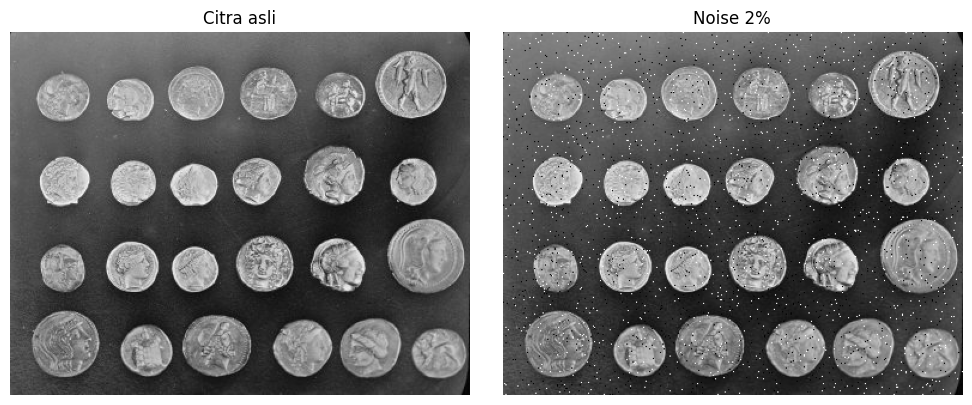

In [13]:
folder_hasil = "Image/Hasil"

if os.path.exists("../Image/coins.png"):
    folder_hasil = "../Image/Hasil"

os.makedirs(folder_hasil, exist_ok=True)


# Menampilkan citra asli dan citra dengan noise.
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Citra asli")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy, cmap="gray", vmin=0, vmax=255)
plt.title("Noise 2%")
plt.axis("off")

plt.tight_layout()
plt.savefig(folder_hasil + "/01_citra_uji.png", dpi=160)
plt.show()


## 14 Hasil pada citra asli

Enam gambar berikut menampilkan Otsu saja, dilation, erosion, opening, closing, dan gabungan opening lalu closing. Perhatikan perubahan ukuran objek, bintik putih pada latar, dan lubang gelap pada permukaan koin.

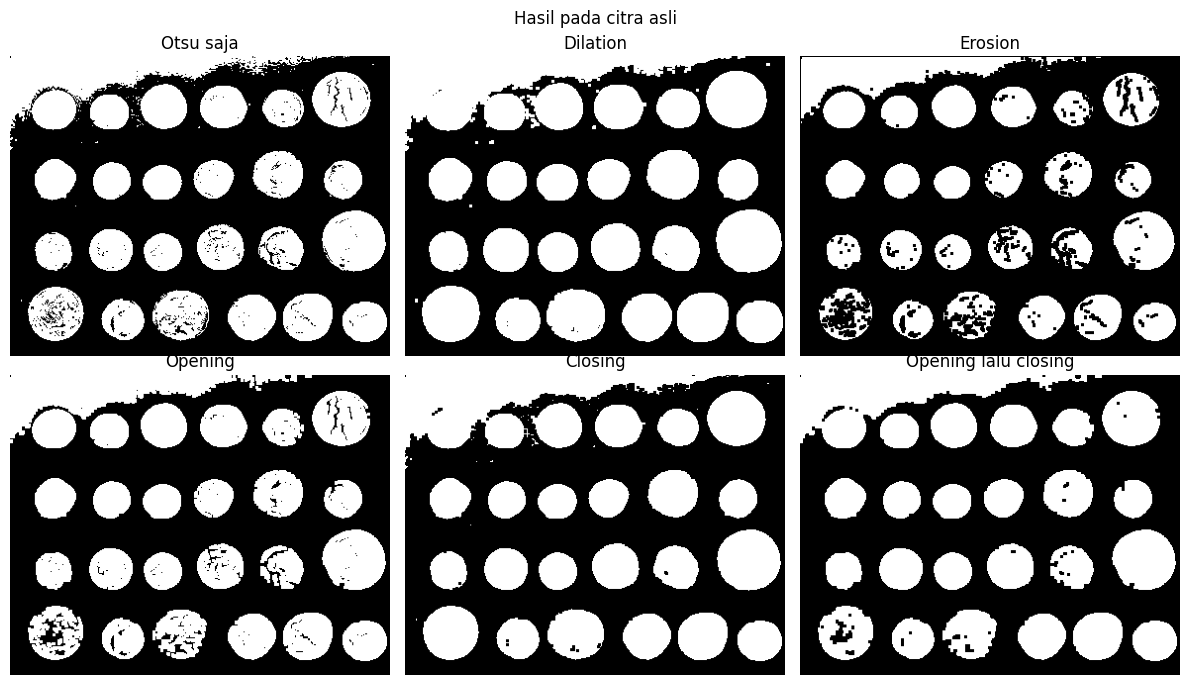

In [14]:
hasil_asli = [biner_asli, dilasi_asli, erosi_asli,
              opening_asli, closing_asli, gabungan_asli]

judul = ["Otsu saja", "Dilation", "Erosion",
         "Opening", "Closing", "Opening lalu closing"]

plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(hasil_asli[i], cmap="gray", vmin=0, vmax=1)
    plt.title(judul[i])
    plt.axis("off")

plt.suptitle("Hasil pada citra asli")
plt.tight_layout()
plt.savefig(folder_hasil + "/02_hasil_asli.png", dpi=160)
plt.show()


## 15 Hasil pada citra dengan noise

Operasi yang sama diterapkan pada citra noisy. Pada kondisi ini, pengaruh opening terhadap bintik putih serta closing terhadap lubang kecil lebih mudah diamati.

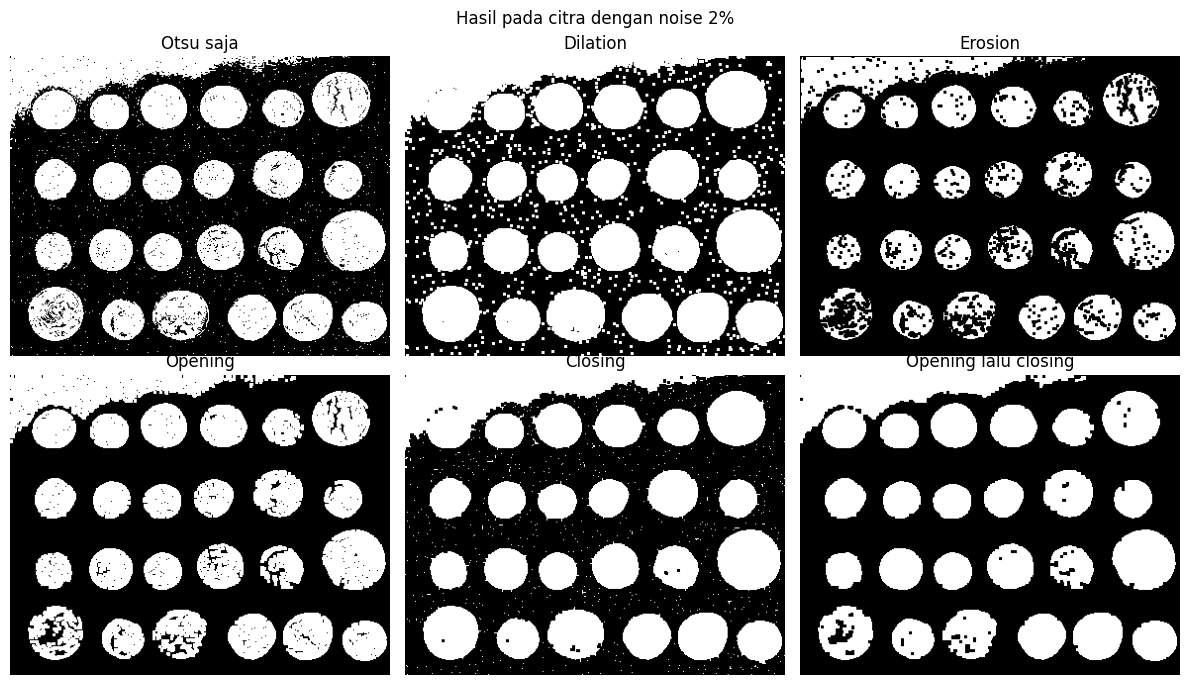

In [15]:
hasil_noisy = [biner_noisy, dilasi_noisy, erosi_noisy,
               opening_noisy, closing_noisy, gabungan_noisy]

plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(hasil_noisy[i], cmap="gray", vmin=0, vmax=1)
    plt.title(judul[i])
    plt.axis("off")

plt.suptitle("Hasil pada citra dengan noise 2%")
plt.tight_layout()
plt.savefig(folder_hasil + "/03_hasil_noise.png", dpi=160)
plt.show()


## 16 Perbandingan tanpa dan dengan morfologi

Perbandingan utama menempatkan hasil Otsu tanpa morfologi di sebelah kiri dan hasil opening lalu closing di sebelah kanan. Saya menggunakan citra noisy supaya perubahan gangguan kecil terlihat lebih jelas.

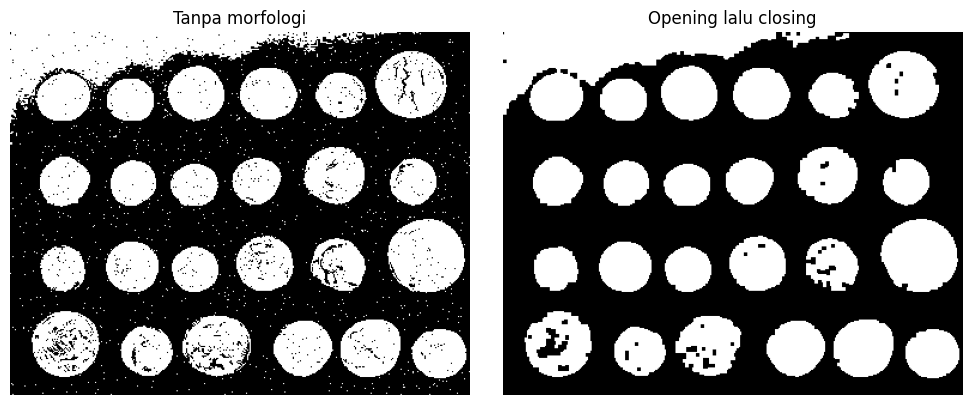

In [16]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(biner_noisy, cmap="gray", vmin=0, vmax=1)
plt.title("Tanpa morfologi")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gabungan_noisy, cmap="gray", vmin=0, vmax=1)
plt.title("Opening lalu closing")
plt.axis("off")

plt.tight_layout()
plt.savefig(folder_hasil + "/04_sebelum_sesudah.png", dpi=160)
plt.show()


Berdasarkan gambar di atas, opening mengurangi bintik putih kecil pada latar. Closing kemudian menutup sebagian lubang hitam kecil pada koin. Hasilnya terlihat lebih bersih dibanding Otsu saja, tetapi bagian latar yang terang di kiri atas masih ikut menjadi objek.

## 17 Kesimpulan

Dilation memperbesar objek, sedangkan erosion memperkecilnya. Opening adalah erosion lalu dilation dan closing adalah dilation lalu erosion. Pada citra uji ini, gabungan opening lalu closing mengurangi bintik dan beberapa lubang kecil. Perbandingan dilakukan dari tampilan gambar, tanpa menyatakan nilai akurasi.